# Version 2 — Does the idea work for other kinds of models?

Version 1 used Logistic Regression and Random Forest. Here the same four-arm comparison is
repeated for **different model families**:

| Family | Model |
|---|---|
| gradient boosting (scikit-learn) | `HistGradientBoostingClassifier` |
| gradient boosting (library) | `XGBClassifier` (if installed) |
| gradient boosting (library) | `CatBoostClassifier` (if installed) |
| neural network | `MLPClassifier` |
| bagged trees (extremely randomized) | `ExtraTreesClassifier` |

Nothing about the method changes: still fixed $\alpha=1,\beta=1$, still PCA-guided removal of the
least impactful features, still repeated stratified CV with identical folds per arm.

## The four results compared in every version

| Arm | What it does | Why it is there |
|---|---|---|
| **A. Naive** | all features, standardized | the baseline: what we would get if we kept everything |
| **B. PCA-guided drop** | PCA ranks features by impact; drop the *k* least impactful, **no compensation** | what a simple practitioner would do |
| **C. Compensate, then drop** | the **same** *k* features as B, but compensated into the rest first (**our idea**) | `C - B` isolates the effect of compensation |
| **D. PCA components** | classic PCA reduction to the same width (*d - k*) | standard reduction reference; loses per-feature meaning |

B and C remove exactly the same features, so any difference between them comes
from the compensation alone. Everything (PCA ranking, scaling, covariances) is
learned inside each cross-validation training fold, so nothing leaks from the test fold.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")

# Make the `ssfc` package importable whether the notebook is opened from the
# repo root or from the notebooks/ folder (VS Code uses the notebook's folder).
ROOT = pathlib.Path.cwd()
if not (ROOT / "ssfc").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from ssfc import *          # SSFC, AutoAlphaSSFC, run_benchmark, paired_summary, plot_arms, ...

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
print("repo root:", ROOT)

repo root: /home/claude/repo


## 1. Models
XGBoost and CatBoost are optional; any that are missing are skipped with a message.

In [2]:
from sklearn.ensemble import HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier

models = {
    "HistGradBoost": HistGradientBoostingClassifier(max_iter=100, random_state=0),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=150, random_state=0, n_jobs=-1),
    "MLP": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=600, early_stopping=True, random_state=0),
}
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1,
                                      eval_metric="logloss", random_state=0, verbosity=0, n_jobs=1)
except ImportError:
    print("xgboost not installed -> skipped (pip install xgboost)")
try:
    from catboost import CatBoostClassifier
    models["CatBoost"] = CatBoostClassifier(iterations=80, depth=4, verbose=0, random_seed=0, thread_count=1,
                                       allow_writing_files=False)
except ImportError:
    print("catboost not installed -> skipped (pip install catboost)")
print("models:", list(models))

models: ['HistGradBoost', 'ExtraTrees', 'MLP', 'XGBoost', 'CatBoost']


## 2. Datasets

In [3]:
datasets = load_many(["breast_cancer", "wine", "pima", "ionosphere"])

loaded breast_cancer  n=   569  d= 30  classes=2  | Breast Cancer Wisconsin (medical, binary)
loaded wine           n=   178  d= 13  classes=3  | Wine chemistry (3 classes)
loaded pima           n=   768  d=  8  classes=2  | Pima Indians Diabetes (8 features, binary)
loaded ionosphere     n=   351  d= 33  classes=2  | Ionosphere radar returns (34 features, binary)


## 3. Four-arm comparison for every model

In [4]:
FRAC_REMOVE, ALPHA, BETA = 0.25, 1.0, 1.0
N_SPLITS, N_REPEATS = 5, 1       # raise N_REPEATS to 2-4 for tighter estimates (slower)

res, folds = run_benchmark(datasets, models, frac_remove=FRAC_REMOVE, alpha=ALPHA, beta=BETA,
                           selection="pca_low", n_splits=N_SPLITS, n_repeats=N_REPEATS)
arm_table(res)

done breast_cancer HistGradBoost          k=8


done breast_cancer ExtraTrees             k=8


done breast_cancer MLP                    k=8


done breast_cancer XGBoost                k=8


done breast_cancer CatBoost               k=8


...

done ionosphere    ExtraTrees             k=8


done ionosphere    MLP                    k=8


done ionosphere    XGBoost                k=8


done ionosphere    CatBoost               k=8


arm                         A_naive_all_features B_drop_no_compensation C_compensate_then_drop D_pca_components
dataset       model                                                                                            
breast_cancer HistGradBoost      0.9907 ± 0.0081        0.9907 ± 0.0087        0.9907 ± 0.0078  0.9901 ± 0.0107
              ExtraTrees         0.9942 ± 0.0052        0.9950 ± 0.0040        0.9901 ± 0.0068  0.9903 ± 0.0030
              MLP                0.9847 ± 0.0136        0.9904 ± 0.0059        0.9804 ± 0.0200  0.9724 ± 0.0337
              XGBoost            0.9931 ± 0.0044        0.9936 ± 0.0044        0.9891 ± 0.0078  0.9914 ± 0.0079
              CatBoost           0.9957 ± 0.0041        0.9952 ± 0.0034        0.9921 ± 0.0069  0.9931 ± 0.0052
wine          HistGradBoost      0.9981 ± 0.0037        0.9945 ± 0.0089        0.9962 ± 0.0028  0.9975 ± 0.0021
              ExtraTrees         0.9991 ± 0.0019        0.9971 ± 0.0037        0.9984 ± 0.0020  0.9991 ± 0.0013
              MLP                0.9777 ± 0.0115        0.8764 ± 0.0835        0.9113 ± 0.0875  0.9865 ± 0.0123
              XGBoost            0.9973 ± 0.0024        0.9926 ± 0.0068        0.9949 ± 0.0049  0.9962 ± 0.0024
              CatBoost           0.9993 ± 0.0009        0.9980 ± 0.0040        0.9962 ± 0.0045  0.9980 ± 0.0021
pima          HistGradBoost      0.7987 ± 0.0323        0.7721 ± 0.0694        0.7827 ± 0.0361  0.7800 ± 0.0351
              ExtraTrees         0.8182 ± 0.0206        0.7893 ± 0.0517        0.8025 ± 0.0334  0.7948 ± 0.0266
              MLP                0.8293 ± 0.0216        0.7424 ± 0.0841        0.7536 ± 0.0565  0.7914 ± 0.0604
              XGBoost            0.8293 ± 0.0256        0.7954 ± 0.0651        0.8020 ± 0.0530  0.7972 ± 0.0349
              CatBoost           0.8400 ± 0.0233        0.8056 ± 0.0730        0.8104 ± 0.0527  0.8149 ± 0.0265
ionosphere    HistGradBoost      0.9685 ± 0.0190        0.9716 ± 0.0150        0.9681 ± 0.0183  0.9792 ± 0.0138
              ExtraTrees         0.9893 ± 0.0068        0.9898 ± 0.0037        0.9826 ± 0.0107  0.9876 ± 0.0112
              MLP                0.9294 ± 0.0300        0.9309 ± 0.0276        0.9336 ± 0.0461  0.8848 ± 0.0807
              XGBoost            0.9638 ± 0.0195        0.9596 ± 0.0212        0.9577 ± 0.0223  0.9758 ± 0.0141
              CatBoost           0.9709 ± 0.0162        0.9718 ± 0.0169        0.9697 ± 0.0148  0.9810 ± 0.0136

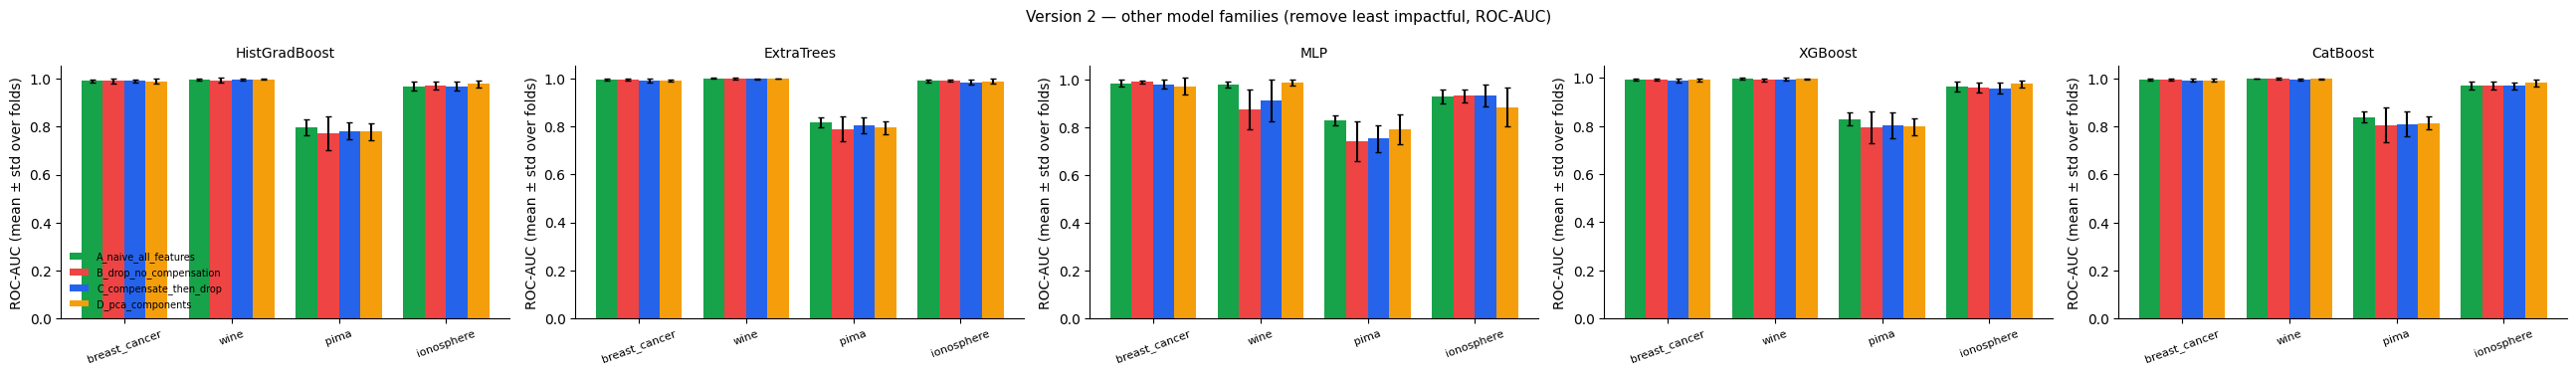

In [5]:
plot_arms(res, title="Version 2 — other model families (remove least impactful, ROC-AUC)")
plt.show()

### Paired summary: compensation (C) vs plain drop (B)

In [6]:
summ = paired_summary(res, folds)
display(summ.round(4))
vc = verdict_counts(summ)
print(f"Over {vc['total']} dataset×model cases: better {vc['better']}, within noise {vc['within_noise']}, worse {vc['worse']}")
print()
print("Mean (C - B) per model family:")
print(summ.groupby("model").comp_minus_drop.mean().round(4).to_string())

,dataset,model,d,k_removed,auc_naive,auc_drop,auc_comp,auc_pca,comp_minus_drop,se,comp_wins_folds
0,breast_cancer,HistGradBoost,30,8,0.9907,0.9907,0.9907,0.9901,0.0001,0.0026,0.4
1,breast_cancer,ExtraTrees,30,8,0.9942,0.9950,0.9901,0.9903,-0.0049,0.0017,0.0
2,breast_cancer,MLP,30,8,0.9847,0.9904,0.9804,0.9724,-0.0100,0.0076,0.4
3,breast_cancer,XGBoost,30,8,0.9931,0.9936,0.9891,0.9914,-0.0044,0.0027,0.2
4,breast_cancer,CatBoost,30,8,0.9957,0.9952,0.9921,0.9931,-0.0031,0.0020,0.2
5,wine,HistGradBoost,13,3,0.9981,0.9945,0.9962,0.9975,0.0017,0.0038,0.2
6,wine,ExtraTrees,13,3,0.9991,0.9971,0.9984,0.9991,0.0013,0.0012,0.4
7,wine,MLP,13,3,0.9777,0.8764,0.9113,0.9865,0.0349,0.0433,0.6
8,wine,XGBoost,13,3,0.9973,0.9926,0.9949,0.9962,0.0023,0.0015,0.6
9,wine,CatBoost,13,3,0.9993,0.9980,0.9962,0.9980,-0.0018,0.0013,0.0


Over 20 dataset×model cases: better 3, within noise 11, worse 6

Mean (C - B) per model family:
model
CatBoost        -0.0006
ExtraTrees       0.0006
HistGradBoost    0.0022
MLP              0.0097
XGBoost          0.0007


## 4. Stress test: remove the MOST impactful features (by PCA)

In [7]:
res_h, folds_h = run_benchmark(datasets, models, frac_remove=FRAC_REMOVE, alpha=ALPHA, beta=BETA,
                               selection="pca_high", n_splits=N_SPLITS, n_repeats=N_REPEATS, verbose=False)
summ_h = paired_summary(res_h, folds_h)
display(summ_h[["dataset", "model", "auc_naive", "auc_drop", "auc_comp", "auc_pca", "comp_minus_drop", "se"]].round(4))
vc = verdict_counts(summ_h)
print(f"Most-impactful removed: better {vc['better']}, within noise {vc['within_noise']}, worse {vc['worse']} of {vc['total']}")

,dataset,model,auc_naive,auc_drop,auc_comp,auc_pca,comp_minus_drop,se
0,breast_cancer,HistGradBoost,0.9907,0.9929,0.9900,0.9901,-0.0028,0.0029
1,breast_cancer,ExtraTrees,0.9942,0.9908,0.9901,0.9903,-0.0007,0.0039
2,breast_cancer,MLP,0.9847,0.9691,0.4146,0.9724,-0.5545,0.2086
3,breast_cancer,XGBoost,0.9931,0.9914,0.9894,0.9914,-0.0020,0.0026
4,breast_cancer,CatBoost,0.9957,0.9903,0.9929,0.9931,0.0026,0.0025
5,wine,HistGradBoost,0.9981,0.9977,0.9938,0.9975,-0.0039,0.0019
6,wine,ExtraTrees,0.9991,0.9993,0.9995,0.9991,0.0002,0.0002
7,wine,MLP,0.9777,0.9386,0.9223,0.9865,-0.0162,0.0112
8,wine,XGBoost,0.9973,0.9977,0.9961,0.9962,-0.0016,0.0011
9,wine,CatBoost,0.9993,0.9993,0.9963,0.9980,-0.0031,0.0015


Most-impactful removed: better 1, within noise 13, worse 6 of 20


In [8]:
pd.concat([res.assign(experiment="remove_least_impactful"),
           res_h.assign(experiment="remove_most_impactful")]).to_csv(RESULTS / "v2_results.csv", index=False)
print("saved results/v2_results.csv")

saved results/v2_results.csv


## 5. Reading the results

* Tree ensembles and boosting are fairly robust to losing a few features, so the A–B gap is
  often tiny and C − B is mostly noise.
* The MLP results vary a lot from fold to fold (large std), so single differences for it are weak evidence.
* If C − B is positive for some family on some dataset, check it again with more CV repeats
  (`N_REPEATS`) before believing it.
* A fixed $\alpha = 1$ is a guess. **Version 4** replaces it by a cross-validated choice that
  includes $\alpha = 0$.

**Next:** `v3_distance_based.ipynb`.